# 2D Modeling of Magmatic Intrusion Cooling with Groundwater Flow
**Riski Basrin — GPGN 536**

## What do I want to understand?
A hot intrusion → heat spreads into the surrounding rock → water flows through the rock → water carries heat → the temperature pattern and cooling change.

My question is: **how does groundwater flow change intrusion cooling and heat spreading in the surrounding rock?**

I compare two cases with the same initial temperature and thermal properties: with flow and without flow. In the no-flow case, water remains in the pores but does not move.

## 1. Define where the process takes place
The domain is 2,000 × 2,000 m, with a 200 × 400 m intrusion at the center. The vertical coordinate z increases downward. It is a local coordinate, not an absolute depth.

Arrays still use **T[j, i]**: vertical row first, horizontal column second. Grid points are at cell centers. Intrusion boundaries lie at cell faces, so its area is exactly 80,000 m².

Keep this notebook in the same folder as `simulation.py` and `plots.py`.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from simulation import Parameters, make_grid, run_pair
from plots import plot_results

# Keep the project parameters visible here. Full defaults are in simulation.py.
p = Parameters(spacing=20.0, width=200.0, height=400.0,
               Tm=1000.0, Tb=100.0, k_host=1.e-15,
               head_left=20.0, head_right=0.0, years=5000.0)
x, z, X, Z, intrusion = make_grid(p)
print("Grid spacing:", p.spacing, "m")
print("Array shape:", intrusion.shape)
print("Intrusion area:", intrusion.sum() * p.spacing**2, "m²")


Grid spacing: 20.0 m
Array shape: (100, 100)
Intrusion area: 80000.0 m²


## 2. Equations and boundary conditions
Steady groundwater flow is calculated from
$$
\nabla\cdot(K\nabla h)=0,\qquad \mathbf q=-K\nabla h,
\qquad K=\frac{k\rho_w g}{\mu_w}.
$$
The head is 20 m at the left boundary and 0 m at the right boundary. Water cannot cross the top or bottom boundary. Intrusion permeability is zero, so water flows around it.

Heat transfer is calculated from
$$
C\frac{\partial T}{\partial t}=\nabla\cdot(\lambda\nabla T)
-\rho_w c_{p,w}\nabla\cdot(\mathbf qT).
$$
The intrusion starts at 1,000°C. The surrounding rock and all four thermal boundaries are at 100°C.

The heat capacity per unit volume of saturated host rock is
$$
C_h=(1-\phi)\rho_r c_{p,r}+\phi\rho_w c_{p,w}.
$$
Inside the intrusion, heat capacity per unit volume is intrusion density multiplied by its specific heat.



In [2]:
# Set the same initial temperature and material properties for both cases.
T_initial = np.full(X.shape, p.Tb, dtype=float)
T_initial[intrusion] = p.Tm

C = np.where(intrusion, p.rho_intrusion * p.cp_intrusion, p.C_host)
lam = np.where(intrusion, p.lambda_intrusion, p.lambda_host)

print("Initial intrusion temperature:", p.Tm, "°C")
print("Initial host-rock temperature:", p.Tb, "°C")
print("Temperature on all four domain boundaries:", p.Tb, "°C")
print("Left/right hydraulic head:", p.head_left, "/", p.head_right, "m")
print("Top/bottom flow boundaries: no water flux")
print("Intrusion permeability: 0 m² (impermeable)")
print("Host-rock volumetric heat capacity:", p.C_host, "J/(m³ K)")


Initial intrusion temperature: 1000.0 °C
Initial host-rock temperature: 100.0 °C
Temperature on all four domain boundaries: 100.0 °C
Left/right hydraulic head: 20.0 / 0.0 m
Top/bottom flow boundaries: no water flux
Intrusion permeability: 0 m² (impermeable)
Host-rock volumetric heat capacity: 2318800.0 J/(m³ K)


## 3. How do I calculate it?
Intercell fluxes connect four neighbors, using harmonic means at material interfaces. Conduction uses **Crank–Nicolson**. After conduction, advection uses **explicit upwinding**. The time step is limited to keep the update controlled.

Crank–Nicolson is second-order in time for smooth conduction. The combination with upwind advection and sequential splitting is generally first-order in time. Centered conduction is second-order in space for a homogeneous smooth case; upwind advection is first-order in space.


The code below prepares the flow field, the conduction matrix, and the time-step estimate. The functions are defined in `simulation.py`, which is also used by the browser application and verification tests.

Inside the time loop, `run_pair` repeats these steps: conduction → advection for the flow case; conduction alone for the no-flow case. The detailed loop is visible in `simulation.py`.


In [3]:
from simulation import solve_flow, conduction_operator, SECONDS_PER_YEAR

# Solve groundwater flow. The intrusion blocks water but conducts heat.
head, qx, qz = solve_flow(p, intrusion)

# Assemble the same conduction operator used by run_pair and verification.
L, b_boundary = conduction_operator(C, lam, p.spacing, p.spacing, p.Tb)

# Inspect the rates used to select the time step.
rate_conduction = np.max(-L.diagonal())
outflow = (
    (np.maximum(qx[:, 1:], 0.0) + np.maximum(-qx[:, :-1], 0.0)) / p.spacing
    + (np.maximum(qz[1:, :], 0.0) + np.maximum(-qz[:-1, :], 0.0)) / p.spacing
)
rate_advection = np.max(p.rho_water * p.cp_water * outflow / C)
dt_conduction = 0.5 / rate_conduction
dt_advection = 0.5 / rate_advection if rate_advection > 0 else np.inf
dt_selected = min(dt_conduction, dt_advection)

print("Conduction matrix shape:", L.shape)
print("Largest horizontal Darcy-flux magnitude:", np.max(np.abs(qx)), "m/s")
print("Largest vertical Darcy-flux magnitude:", np.max(np.abs(qz)), "m/s")
print("Selected time step before final-time adjustment:",
      dt_selected / SECONDS_PER_YEAR, "years")
print("Advective CFL before final-time adjustment:", dt_selected * rate_advection)


Conduction matrix shape: (10000, 10000)
Largest horizontal Darcy-flux magnitude: 8.064115202108398e-10 m/s
Largest vertical Darcy-flux magnitude: 6.646974093455525e-10 m/s
Selected time step before final-time adjustment: 0.979711173642271 years
Advective CFL before final-time adjustment: 0.0031585384362121482


## 4. Run the two cases
Both cases start from the same initial temperature. Do not use the final temperature of one case as the initial temperature of the other.

The saved outputs below come from the already computed default example. Running this cell in Jupyter performs a fresh simulation.

**Run the code cell immediately below.** It starts both cases from the original temperature, performs all time steps through `run_pair`, and saves the histories and temperature maps in `r`. The next section uses this result to make the figures.


In [4]:
# Run until both cases are complete.
r = run_pair(p)
print("Simulation completed.")
print("Number of time steps:", r["n_steps"])
print("Actual dt:", r["dt_years"], "years")
print("Center without flow:", r["center_no_flow"][-1], "°C")
print("Center with flow:", r["center_flow"][-1], "°C")
print("Difference (no flow − with flow):",
      r["center_no_flow"][-1] - r["center_flow"][-1], "°C")
print("Largest difference between the final maps:",
      r["max_final_map_difference"], "°C")


Simulation completed.
Number of time steps: 5104
Actual dt: 0.9796238244514106 years
Center without flow: 140.41635388534624 °C
Center with flow: 140.08085959654852 °C
Difference (no flow − with flow): 0.3354942887977188 °C
Largest difference between the final maps: 2.8381480086259785 °C


## 5. Look at the results
My three main outputs are the flow map, the temperature maps, and the cooling curves.

Arrows show water flowing around the intrusion. The temperature maps use the same color scale. Darker colors at late times show cooling, but they do not mean the whole domain is exactly 100°C.

On a cell-centered grid, the geometric center lies between four cells. The reported center temperature is the average of those nearest cells, rather than the old [50, 50] node value.


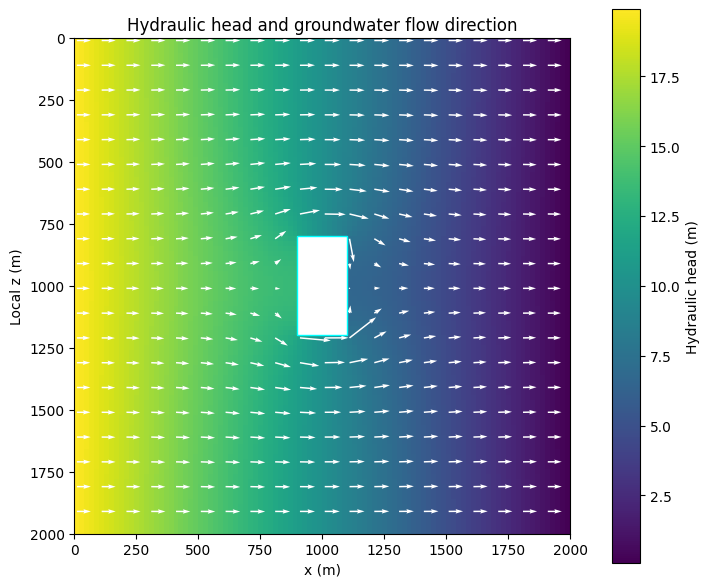

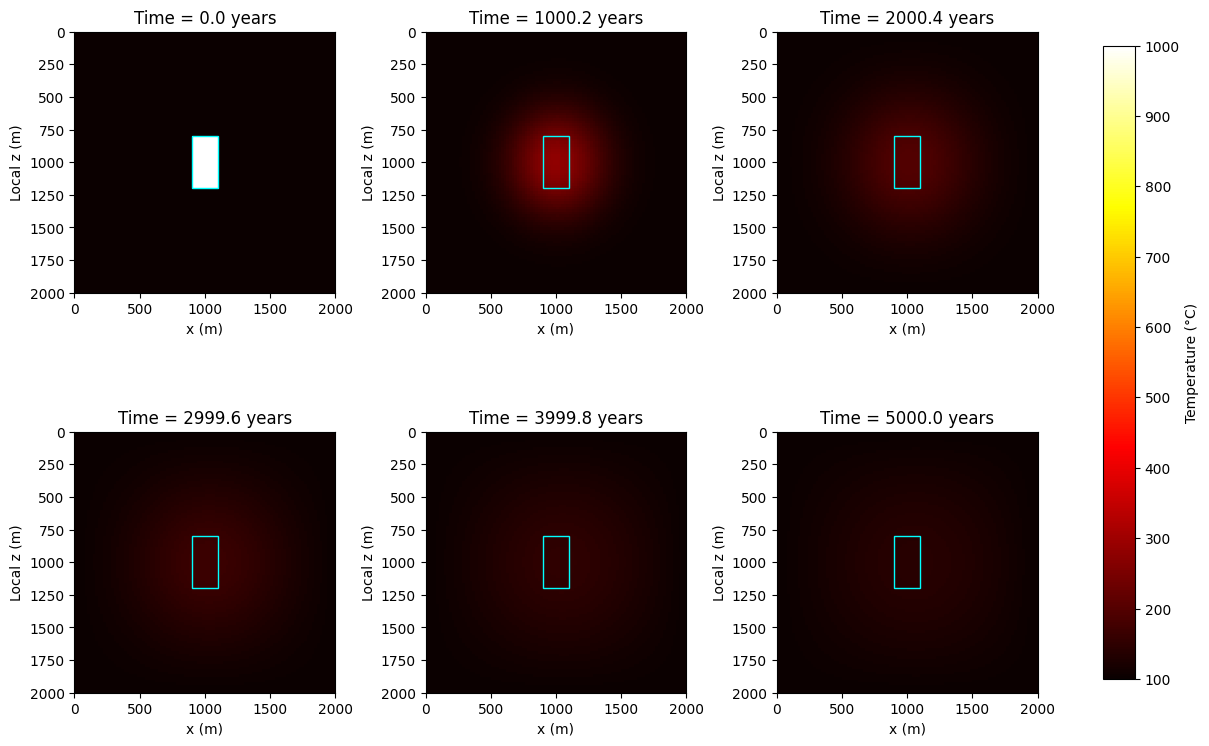

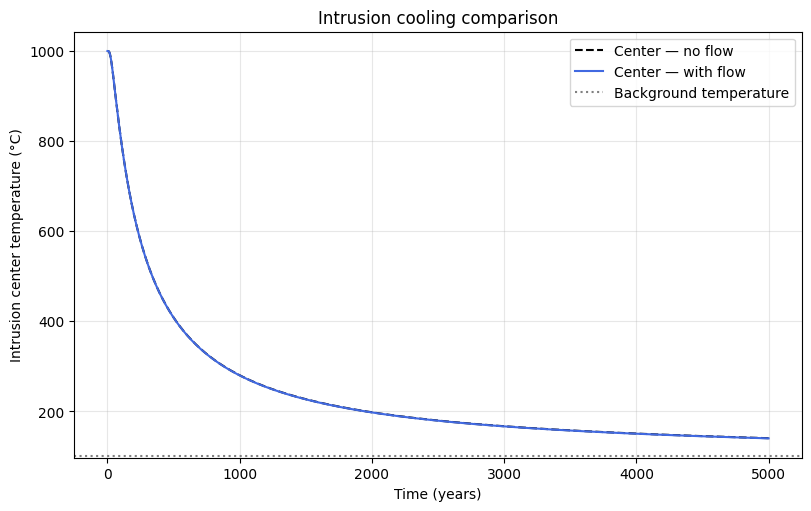

In [5]:
figures = plot_results(r)
plt.show()


## 6. Discussion
For the default parameters, I read the center-temperature effect from the numerical difference because the curves can nearly overlap. The effect at the center is not automatically the same as the effect across the whole surrounding rock.

These results replace the earlier oversized-grid geometry results. The old values of 146.212°C and a 0.361°C difference are not used as results for the corrected geometry.

Differences between cases include physical advection and numerical effects from upwinding. Actual intrusion refinement results are stored in `results/summary.json`. I compare the grid sensitivity with the size of the flow effect.



## 7. Model limitations
I use fixed background flow. Temperature does not change density, viscosity, or permeability. I omit latent heat, water phase changes, and buoyancy-driven convection. This is an idealized model for understanding a mechanism, rather than a field prediction.

Material properties, porosity, permeability, and initial intrusion temperature match Table 2 of Fu et al. (2010). Rock conductivity of 2.5 W/(m K) is used as an effective saturated-rock approximation. Geometry, background temperature, duration, and head are my scenario choices. Full references are in the README.

## Where does this project end?
My final outputs are the three figures above, the comparison between cases, and verification in a separate notebook. The browser interface calls the same Python solver. No additional physical processes are needed to run this version.


## Final results and how I read them

At 5,000 years, the results for an exact 200 × 400 m intrusion are:

| Check | Center without flow (°C) | Center with flow (°C) | Difference (°C) |
|---|---:|---:|---:|
| 20 m grid | 140.416354 | 140.080860 | 0.335494 |
| 20 m grid, dt/2 | 140.416354 | 140.080831 | 0.335523 |
| 10 m grid | 140.413347 | 140.131174 | 0.282174 |

Halving dt on the same grid changes the difference between the cases by 0.000029°C. Refining the grid from 20 m to 10 m changes that difference by 0.053321°C, approximately 15.9% of the 20 m result. On the 10 m grid, dt is also adjusted using the same selection rule.

At both tested resolutions, the center is slightly cooler with flow, and the cooling curves nearly overlap. I do not claim that a particular difference is a converged physical effect. Upwind advection adds numerical diffusion.

The effect in the surrounding rock is different from the center effect. The largest difference between the final maps is approximately 2.838°C on the 20 m grid and 2.830°C on the 10 m grid. This compares the two cases; it is not an error against an exact solution.
